### Exercice 7 : Le Filtre Anti-Spam (Analyse puis Décision)
Objectif : Combiner un nœud d'analyse séquentiel suivi d'un aiguillage conditionnel basé sur le
résultat de cette analyse.
Étape 1 (Analyse) : Le nœud analyze_node inspecte le texte à la recherche de mots interdits et
remplit le booléen is_spam .
Étape 2 (Décision) : Le routeur lit is_spam (True ou False) pour envoyer le message vers la
corbeille ou la boîte de réception.

In [1]:
from langgraph.graph import  StateGraph, END,START
from typing import TypedDict

In [2]:
class SpamState(TypedDict):
    text:str
    is_spam:bool

In [4]:
def analyze_node(state:SpamState):
    state['text'].find( "spam")

def reception(state:SpamState):
    return "reception"

def corbeille(state:SpamState):
    return "corbeille"

def router(state:SpamState):

    if state["is_spam"]== True:
        return "reception_nd"
    else:
        return "corbeille_nd"


In [5]:
workflow = StateGraph(SpamState)
workflow.add_node('analyze_node',analyze_node)
workflow.add_node('reception_node',reception)
workflow.add_node('corbeille_node',corbeille)

workflow.add_edge(START,"analyze_node")

workflow.add_conditional_edges(
    "analyze_node",router, {
        "reception_nd":"reception_node",
        "corbeille_nd":"corbeille_node"
    }
)
app = workflow.compile()



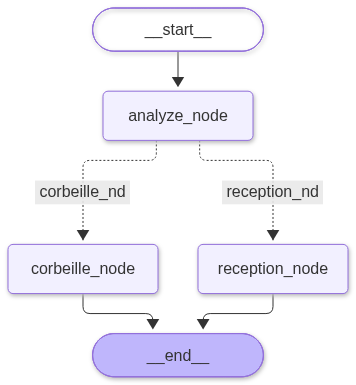

In [6]:
from IPython.display import Image,display
display(Image(app.get_graph().draw_mermaid_png()))